# Clase 10 — Analizando el catálogo de Netflix

En este ejercicio asumirás el rol de un **Data Analyst** dentro de Netflix. El equipo de negocio quiere entender mejor cómo está distribuido el catálogo de la plataforma para tomar decisiones sobre futuras inversiones en contenido.

Para ello deberás utilizar las herramientas aprendidas en esta clase:

- `groupby()`
- funciones de agregación
- `agg()`
- `pivot_table()`
- `unstack()`
- gráficos con Pandas y Matplotlib

> No utilices bucles (`for`) para resolver los ejercicios.


## Parte 1: Exploración del dataset

Antes de comenzar el análisis responde:

1. Carga el dataset.
2. Muestra las primeras filas.
3. ¿Cuántas filas y columnas posee?
4. ¿Qué tipo de dato tiene cada columna?
5. ¿Existen valores nulos?
6. ¿Qué columnas presentan mayor cantidad de valores faltantes?

In [1]:
# tú código acá
import pandas as pd
df = pd.read_csv("netflix_data.csv")


In [8]:
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
df.shape

(8807, 12)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


## Parte 2: Agrupaciones

### Ejercicio 1 - ¿Cuántos títulos existen por país?

Ordena el resultado de mayor a menor.


In [16]:
#cuantos titulos existen por pais? ordenalos de mayor a menor
df.groupby("country")["title"].count().sort_values(ascending=False)



country
United States          2818
India                   972
United Kingdom          419
Japan                   245
South Korea             199
                       ... 
Australia, Iraq           1
Venezuela                 1
Venezuela, Colombia       1
West Germany              1
, South Korea             1
Name: title, Length: 748, dtype: int64

### Ejercicio 2 - ¿Cuántas películas y cuántas series tiene Netflix?

In [19]:
# tu código acá
df.groupby("type")["title"].count()

type
Movie      6131
TV Show    2676
Name: title, dtype: int64

### Ejercicio 3 - ¿Cuántos títulos fueron lanzados cada año?

Ordena el resultado cronológicamente.


In [24]:
# tu código acá
df.groupby("release_year")["title"].count().sort_index()

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: title, Length: 74, dtype: int64

### Ejercicio 4 - ¿Cuál es la clasificación por edades más frecuente?

Por ejemplo:

- TV-MA
- TV-14
- PG
- R

In [26]:
# tu código acá
df['rating'].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

### Ejercicio 5 - Obtén para cada tipo de contenido (Movie y TV Show):

- cantidad de títulos
- año promedio de lanzamiento
- año más reciente
- año más antiguo

> Utiliza **agg()**.

In [34]:
# tu código acá
df.groupby("type").agg(
    cantidad_titulos = ("title", "count"),
    promedio_anio = ("release_year", "mean"),
    anio_reciente = ("release_year", "max"),
    anio_antiguo = ("release_year", "min")
).astype(int)

,cantidad_titulos,promedio_anio,anio_reciente,anio_antiguo
type,,,,
Movie,6131,2013,2021,1942
TV Show,2676,2016,2021,1925


## Parte 3: Agrupaciones múltiples

### Ejercicio 6 - Obtén la cantidad de títulos para cada combinación.

Agrupa por:

- país
- tipo de contenido

In [35]:
# tu código acá
df.groupby(["country", "type"])["title"].count().sort_values(ascending=False)

country                            type   
United States                      Movie      2058
India                              Movie       893
United States                      TV Show     760
United Kingdom                     TV Show     213
                                   Movie       206
                                              ... 
Argentina, Uruguay, Spain, France  Movie         1
Argentina, Uruguay, Serbia         Movie         1
Argentina, United States, Mexico   TV Show       1
Argentina, United States           Movie         1
Argentina, Spain                   TV Show       1
Name: title, Length: 847, dtype: int64

### Ejercicio 7 - Convierte el resultado anterior en una tabla donde:

- las filas sean los países
- las columnas sean Movie y TV Show

> Utiliza **unstack()**.

In [42]:
# tu código acá
tabla = df.groupby(["country", "type"])["title"].count()

tabla_final = tabla.unstack(level=1)
tabla_final = tabla_final.sort_values(by="Movie", ascending=False)
print(tabla_final)

type                                Movie  TV Show
country                                           
United States                      2058.0    760.0
India                               893.0     79.0
United Kingdom                      206.0    213.0
Canada                              122.0     59.0
Spain                                97.0     48.0
...                                   ...      ...
United States, New Zealand, Japan     NaN      1.0
United States, Poland                 NaN      1.0
United States, Singapore              NaN      1.0
United States, South Korea, China     NaN      2.0
Uruguay, Germany                      NaN      1.0

[748 rows x 2 columns]


## Parte 4: Tablas dinámicas

### Ejercicio 8 - Construye una tabla dinámica donde:

- filas → país
- columnas → tipo de contenido
- valores → cantidad de títulos

In [52]:
# tu código acá
tabla_dinamica = df.pivot_table(
    values = "title",
    index = "country",
    columns = "type",
    aggfunc = "count"
).fillna(0)
print(tabla_dinamica.sort_values(by="Movie", ascending=False))

type                         Movie  TV Show
country                                    
United States               2058.0    760.0
India                        893.0     79.0
United Kingdom               206.0    213.0
Canada                       122.0     59.0
Spain                         97.0     48.0
...                            ...      ...
Canada, Japan, Netherlands     0.0      1.0
Brazil, United Kingdom         0.0      1.0
Austria, Germany               0.0      1.0
Belarus                        0.0      1.0
, South Korea                  0.0      1.0

[748 rows x 2 columns]


### Ejercicio 9 - Construye otra tabla dinámica donde:

- filas → clasificación por edades
- columnas → tipo de contenido
- valores → cantidad de títulos

In [51]:
# tu código acá
tabla_dinamica2 = df.pivot_table(
    values = "title",
    index = "rating",
    columns = "type",
    aggfunc = "count"
).fillna(0)
print(tabla_dinamica2)

type       Movie  TV Show
rating                   
66 min       1.0      0.0
74 min       1.0      0.0
84 min       1.0      0.0
G           41.0      0.0
NC-17        3.0      0.0
NR          75.0      5.0
PG         287.0      0.0
PG-13      490.0      0.0
R          797.0      2.0
TV-14     1427.0    733.0
TV-G       126.0     94.0
TV-MA     2062.0   1145.0
TV-PG      540.0    323.0
TV-Y       131.0    176.0
TV-Y7      139.0    195.0
TV-Y7-FV     5.0      1.0
UR           3.0      0.0


### Ejercicio 10 - Modifica la tabla dinámica para que los valores faltantes aparezcan como **0**.

In [ ]:
# tu código acá

## Parte 5: Visualización

### Ejercicio 11 - Genera un gráfico de barras con el **Top 10 países con mayor cantidad de títulos**.

El gráfico debe incluir:

- título
- tamaño de figura
- etiquetas rotadas
- eje Y con nombre


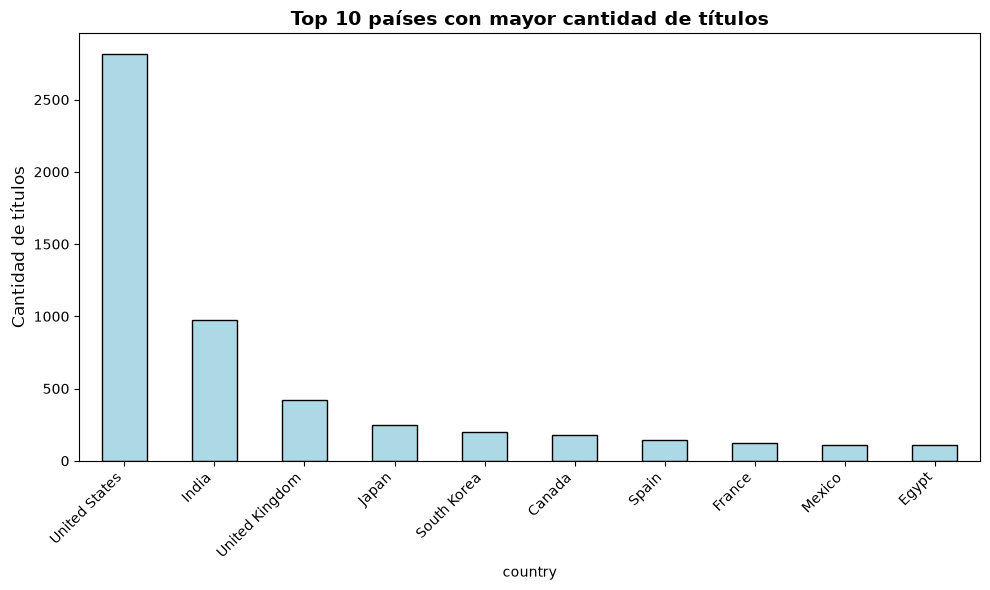

In [57]:
# tu código acá
import matplotlib.pyplot as plt

# 1. Obtener el Top 10 de países con más títulos
top_paises = df["country"].value_counts().head(10)

# 2. Configurar el tamaño de la figura
plt.figure(figsize=(10, 6))

# 3. Generar el gráfico de barras
top_paises.plot(kind="bar", color="lightblue", edgecolor="black")

# 4. Agregar el título y el nombre al eje Y
plt.title("Top 10 países con mayor cantidad de títulos", fontsize=14, fontweight="bold")
plt.ylabel("Cantidad de títulos", fontsize=12)

# 5. Rotar las etiquetas del eje X (los nombres de los países)
plt.xticks(rotation=45, ha="right")

# 6. Mostrar el gráfico de forma limpia
plt.tight_layout()
plt.show()

### Ejercicio 12 - Genera un gráfico de barras mostrando la cantidad de:

- Movies
- TV Shows

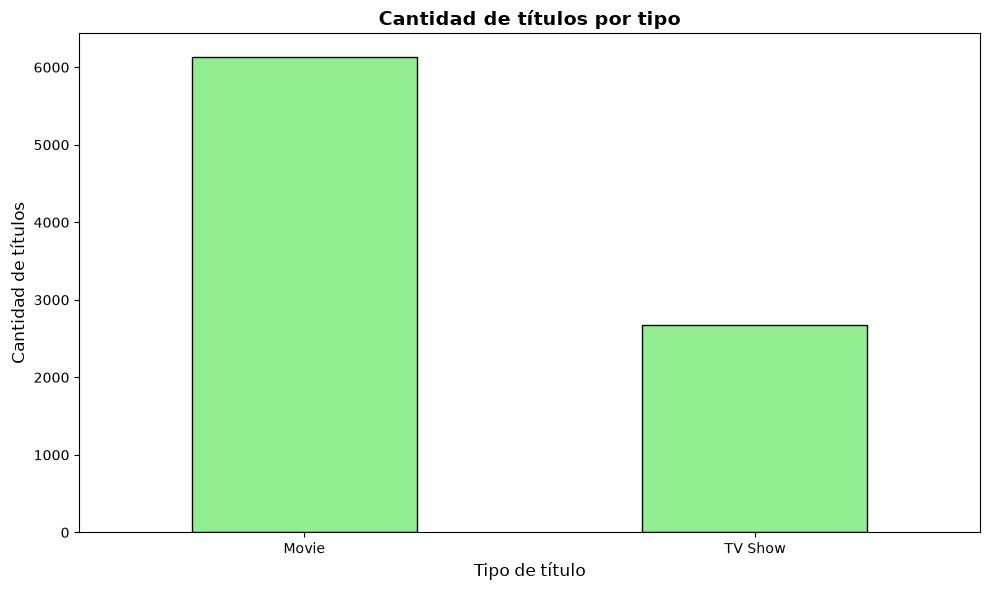

In [59]:
# tu código acá

cant_tipos = df.groupby("type")["title"].count()

plt.figure(figsize=(10, 6))

cant_tipos.plot(kind="bar", color="lightgreen", edgecolor="black")

plt.title("Cantidad de títulos por tipo", fontsize=14, fontweight="bold")
plt.ylabel("Cantidad de títulos", fontsize=12)
plt.xlabel("Tipo de título", fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Ejercicio 13 - Utilizando la tabla dinámica, crea un gráfico de barras agrupadas que compare películas y series por país.


In [ ]:
# tu código acá

## Parte 6: Análisis

Redacta al menos **cinco insights** basados en el análisis realizado. Algunas preguntas que puedes responder son:

- ¿Qué país domina el catálogo?
- ¿Netflix posee más películas o más series?
- ¿Qué clasificación por edades es la más utilizada?
- ¿Existen países donde predominen las series?
- ¿Qué tendencia observas respecto al año de lanzamiento de los contenidos?

Justifica cada respuesta utilizando los datos obtenidos.

In [ ]:
# tu código acá

## Desafío

Netflix desea aumentar su presencia en Latinoamérica. Analiza únicamente los siguientes países:

- Argentina
- Brasil
- Chile
- Colombia
- México
- Perú

Responde:

1. ¿Cuál aporta mayor cantidad de contenido?
2. ¿Predominan las películas o las series?
3. ¿Qué clasificación por edades es la más común?
4. Genera un gráfico comparativo.
5. Escribe una breve recomendación para el director regional de Netflix basada en tus resultados.


In [ ]:
# tu código acá